Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

df.head()   

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

1. Crosstab Analysis:

    · Create a crosstab between the product category and the isBestSeller status.

In [5]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


    · Are there categories where being a best-seller is more prevalent?

In [7]:
# Get the % of True (best-sellers) for each category
df['isBestSeller_pct'] = df.groupby('category')['isBestSeller'].transform('mean')

# Sort by highest percentage first
top_winners = df.groupby('category')['isBestSeller_pct'].mean().sort_values(ascending=False)

# Show top 10
print(top_winners.head(10))

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: isBestSeller_pct, dtype: float64


In [8]:
print(top_winners.to_string())

category
Grocery                                             0.058135
Smart Home Security & Lighting                      0.057692
Health & Personal Care                              0.057686
Mobile Phone Accessories                            0.042471
Power & Hand Tools                                  0.035339
Billiard, Snooker & Pool                            0.032129
Pet Supplies                                        0.030200
Home Brewing & Wine Making                          0.028455
Mirrors                                             0.028000
Wind Instruments                                    0.028000
Professional Medical Supplies                       0.027344
PC & Video Games                                    0.025466
Bakeware                                            0.025105
Material Handling Products                          0.025000
Bedding Accessories                                 0.024390
Tableware                                           0.024096
Arts & Crafts  

1. Are there categories where being a best-seller is more prevalent?

Yes, best-seller prevalence varies significantly by category, with Grocery leading at 5.8% of its items being best-sellers, followed closely by Smart Home Security and Health & Personal Care at 5.7%.

In contrast, large categories like Women (1.2%) and niche ones like 3D Printers (0.4%) have much lower success rates, proving that category size doesn't guarantee best-seller status.

This indicates that high-prevalence categories are often those with frequent, repeat purchases (like food) or trending tech, rather than just those with the highest total volume.

Therefore, being a best-seller is indeed more prevalent in specific niches, where a much larger proportion of the total inventory achieves that status compared to broader markets.

2. Statistical Tests:

    · Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [9]:
from scipy.stats import chi2_contingency

chi2_contingency(crosstab)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

·P-value = 0.0: Since the p-value is essentially zero (far below 0.05), we reject the null hypothesis.
·Conclusion: There is a statistically significant relationship between product category and best-seller status. They are not independent. The fact that an item is a best-seller does depend on which category it is in.

In [10]:
from scipy.stats.contingency import association

association(crosstab, method = "cramer")

0.1222829439760564

2. Compute Cramér's V to understand the strength of association between best-seller status and category.

    · Cramér's V (association):

·Value ≈ 0.122: This measures the strength of the association.
·0 = No association
·0.1 = Weak
·0.3 = Moderate
·0.5 = Strong
·Conclusion: The association is weak. While the relationship is statistically real (due to the massive sample size), the category only explains a small portion of the variance in best-seller status. Other factors (price, reviews, marketing) likely play a bigger role.

The Chi-square test confirms a significant dependency between category and best-seller status (p < 0.05). However, Cramér's V (0.122) indicates this association is weak, suggesting that while category matters, it is not the sole predictor of best-seller success.

3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

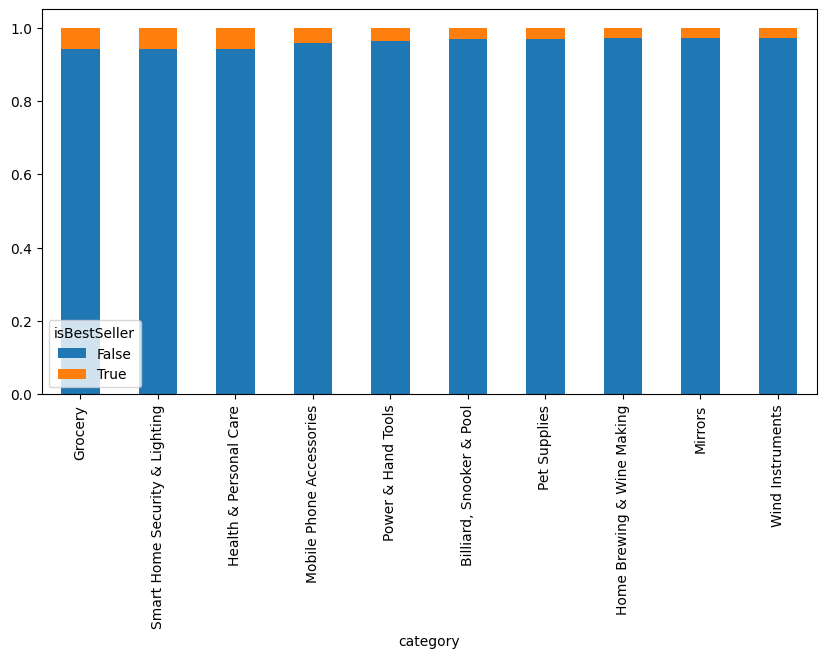

In [11]:
crosstab_pct = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)

top10 = crosstab_pct[True].sort_values(ascending=False).head(10).index

crosstab_pct.loc[top10].plot(kind="bar", stacked=True, figsize=(10,5))

Grocery has the highest proportion of best-sellers (~5.8%), followed closely by Smart Home Security & Lighting and Health & Personal Care.
In all top categories, non-best-sellers still represent more than 94% of products.
The differences between categories exist, but they are relatively small overall.

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [12]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [13]:
data_series = df['price']  
outliers = tukeys_test_outliers(data_series)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [14]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

df_no_outliers = df[(df["price"] >= Q1 - 1.5*IQR) & (df["price"] <= Q3 + 1.5*IQR)]
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category,isBestSeller_pct
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,0.001372
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers,0.001372
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,0.001372
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers,0.001372
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers,0.001372
...,...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing,0.018595
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing,0.018595
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing,0.018595
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing,0.018595


1. Violin Plots:

· Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

In [15]:
# Get top 20 categories by count
top_categories = df_no_outliers["category"].value_counts().head(20).index

# Filter dataframe
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top_categories)]

C:\Users\sfern\AppData\Local\Temp\ipykernel_10732\1605095994.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x="price", y="category", palette="coolwarm")


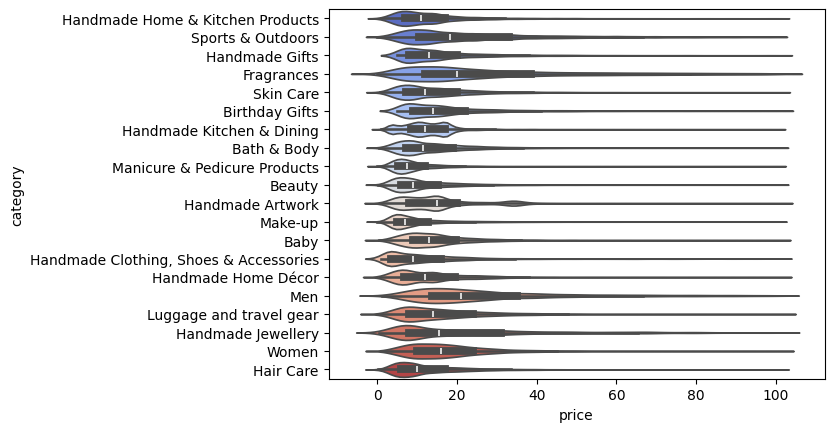

In [16]:
sns.violinplot(data=df_top20, x="price", y="category", palette="coolwarm")
plt.show()

The graphic displays price distributions for the top 20 most frequent product categories. The width of each "violin" shows where prices are most concentrated, while the internal marker (usually a dot or line) indicates the median price for that category. 

The key takeaway: high sales volume (top 20 by count) ≠ high prices. The most popular categories are mostly cheap items, while the pricier ones (like Laptops, which isn't even on this chart) sell less frequently.

·Which product category tends to have the highest median price? Don't filter here by top categories.

In [17]:
# Find the category with the highest median price (using ALL data)
median_prices = df_no_outliers.groupby('category')['price'].median()
best_category = median_prices.idxmax()

print(best_category)   

Desktop PCs


That confirms exactly why we had to run the code on the full dataset instead of just looking at the chart.

The "Top 20 Categories" plot only shows items with the highest sales volume (count). Since Desktop PCs are expensive and bought less frequently than cheap items like phone cases or cables, they didn't make the cut for the top 20 by count. However, this calculation scanned every single category in the database, revealing that even though Desktop PCs aren't on the chart, they still have the highest median price overall. The graph shows what sells most, but we now found what sells highest.

2. Bar Charts:

    · Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

C:\Users\sfern\AppData\Local\Temp\ipykernel_10732\2515934684.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm")


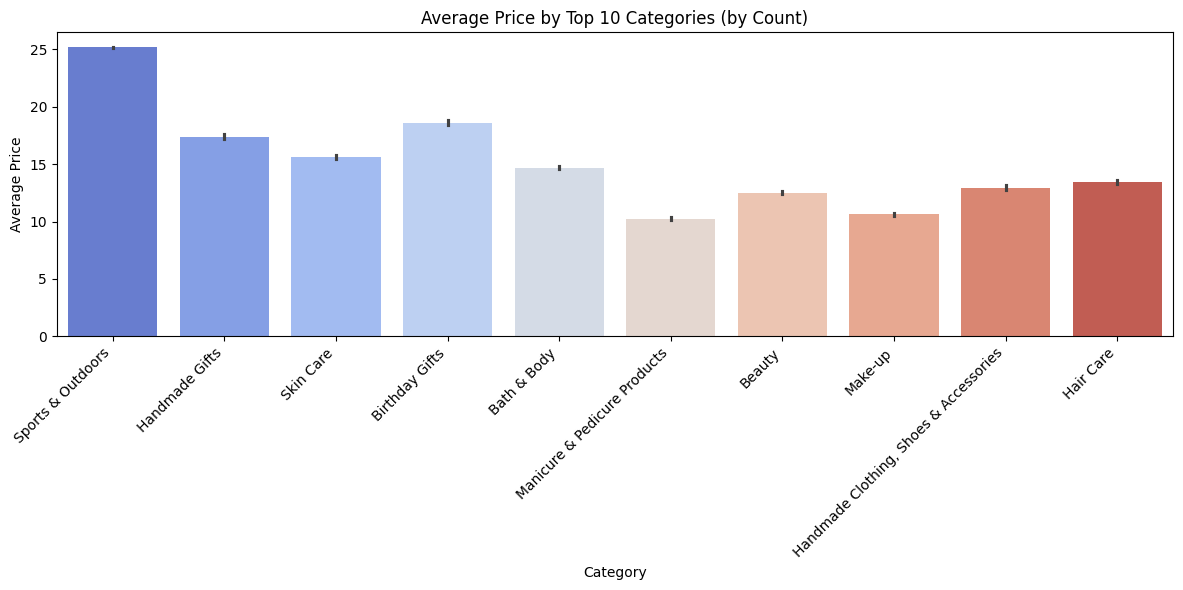

In [18]:
# Step 1: Get the top 10 categories by count
top_categories = df_no_outliers["category"].value_counts().head(10).index

# Step 2: Filter the dataframe to only those categories
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top_categories)]

# Step 3: Plot average price for just those 10
plt.figure(figsize=(12, 6))
sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm")

plt.xticks(rotation=45, ha='right')
plt.title("Average Price by Top 10 Categories (by Count)")
plt.xlabel("Category")
plt.ylabel("Average Price")

plt.tight_layout()
plt.show()

Basically, the chart shows that Sports & Outdoors gear is the most expensive on average, while everyday beauty and personal care items cost less. It’s a simple look at how active lifestyle products tend to have a higher price tag compared to stuff like skincare or hair care in this dataset.

 · Which product category commands the highest average price? Don't filter here by top categories.

In [19]:
# Find the category with the highest average price (using ALL data)
average_prices = df_no_outliers.groupby('category')['price'].mean()
highest_avg_price_category = average_prices.idxmax()

print(highest_avg_price_category)   

Motherboards


Highest Average Price: Motherboards top this list despite likely having fewer total sales than other products shown in the graphic, given its tech complexity and its dependancies within computer devices as more expensive and long term investment products.

3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

In [24]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category', 'isBestSeller_pct'],
      dtype='str')

C:\Users\sfern\AppData\Local\Temp\ipykernel_10732\3054018278.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm")


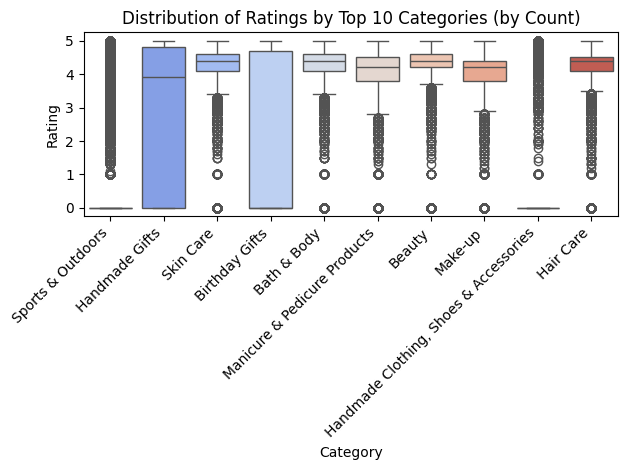

In [25]:
sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm")

plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Ratings by Top 10 Categories (by Count)")
plt.xlabel("Category")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

Most top-10 categories cluster tightly between 4–5 stars, with only scattered low outliers.
Sports & Outdoors and Handmade Clothing, Shoes & Accessories break that pattern — their boxes sit near 0, suggesting a large share of unrated/0-star products. That's a real anomaly, likely driven by many new listings without reviews yet, rather than genuinely poor ratings.

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [26]:
# Find the category with the highest median rating (using ALL data)
median_ratings = df_no_outliers.groupby('category')['stars'].median()
best_rated_category = median_ratings.idxmax()

print(best_rated_category)

Computer Memory


Interesting that this one doesn't show up in the top-10-by-count list from earlier. It's also a different category entirely from the highest average/median price categories we found before. Same idea as the Desktop PCs example: a category can dominate on one metric (here, ratings) without ever being in the "most sold" or "most expensive" spotlight.

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

In [27]:
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])
print(correlation)

-0.07767299878181444


The correlation between price and rating is -0.078, essentially negligible. This means price barely predicts rating at all — expensive products aren't meaningfully rated higher or lower than cheap ones. In short, product price and customer satisfaction (as measured by stars) appear to be independent of each other.

Visualizations:

-Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

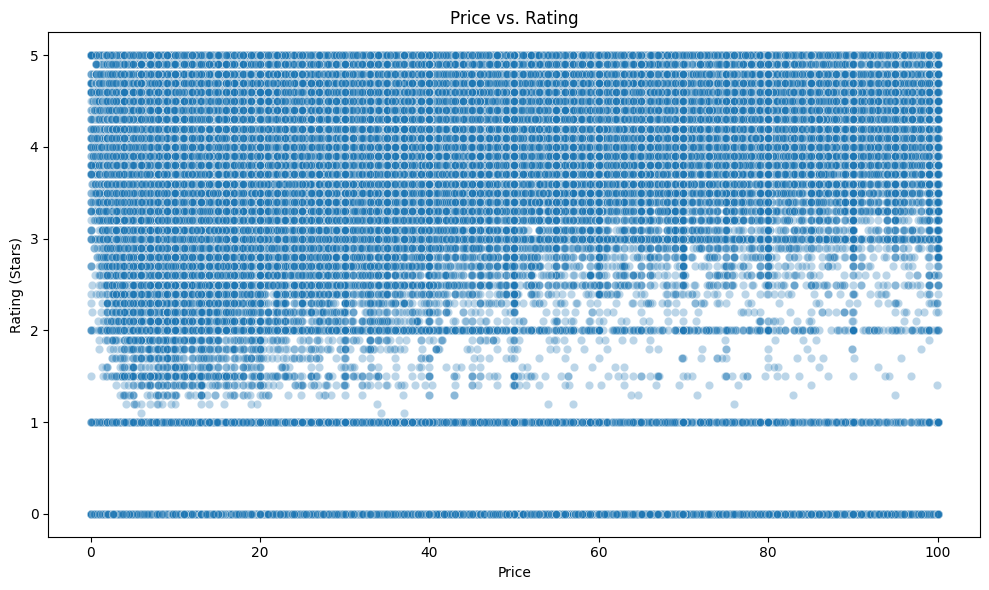

In [29]:
#-Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_no_outliers, x="price", y="stars", alpha=0.3)

plt.title("Price vs. Rating")
plt.xlabel("Price")
plt.ylabel("Rating (Stars)")

plt.tight_layout()
plt.show()

Ratings and prices show no clear relationship — high, mid, and low ratings all appear spread evenly across the full price range ($0–100), with no upward or downward trend as price increases. Ratings cluster into distinct horizontal bands (0, 1, 2, 3, 4, 5) rather than a smooth spread, since stars appears to be rounded. The flat line of points at exactly 0 stands out as unusual — likely unrated products rather than genuine 1-star-or-worse reviews, and worth flagging separately from the real rating pattern.

-Use a correlation heatmap to visualize correlations between all numerical variables.

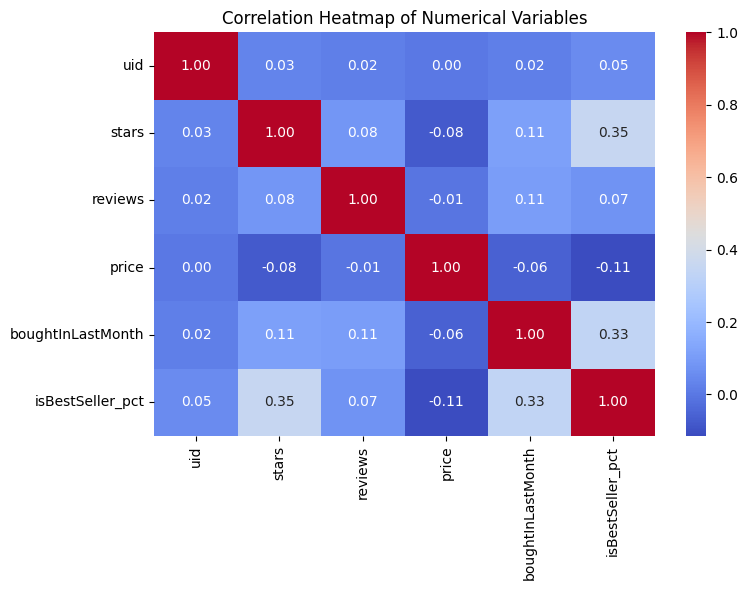

In [31]:
# Select only numeric columns
numeric_cols = df_no_outliers.select_dtypes(include="number")

# Compute correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

The correlation heatmap confirms weak-to-negligible relationships across most numeric variables, with price barely correlating with anything (all values under ±0.11). The strongest relationships are isBestSeller_pct with stars (0.35) and boughtInLastMonth (0.33), suggesting best-seller-heavy categories tend to have higher ratings and more recent purchases. Overall, no strong linear relationships (above 0.5) exist between any pair of numerical variables in this dataset.

Submission: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.

The dataset is heavily dominated by "Sports & Outdoors" (over 90% of listings), with the remaining 295 categories only lightly represented in comparison. 

Prices are extremely right-skewed — the mean (£89.24) is inflated by rare outliers up to £100,000, while the typical product is cheap (median £19.09, mode £9.99).

Visualizations confirm nearly all products fall under £200, with the wide range driven by a handful of extreme cases. 

Ratings are bimodal and polarized: most products have no rating at all, making the mean (2.15) misleading rather than representative. 

Category weakly predicts best-seller status, and price shows almost no relationship with rating — charging more doesn't signal higher perceived quality. 

The clearest relationship is that best-seller share moderately tracks ratings and recent purchases, suggesting popularity and quality reinforce each other more than price does. 

Overall, pricing and catalog strategy should be driven by category-specific demand and data-quality cleanup (unrated items), not assumptions about price signaling quality.